In [11]:
from langgraph.graph import StateGraph , START, END
from typing import TypedDict

In [12]:
class bmi_state(TypedDict):
  weight_kg : float
  height_cm: float
  bmi : float
  category :str
  

In [13]:
def bmi_calculator(state :bmi_state) -> bmi_state:
  weight=state['weight_kg']
  height=state['height_cm']
  bmi=weight/ (height **2)


  state['bmi']= round(bmi, 2)

  return state

  


In [14]:
def label_bmi(state : bmi_state)-> bmi_state:
  bmi=state['bmi']


  if bmi < 18.5:
    state["category"] = "Underweight"
  elif 18.5 <= bmi < 25:
    state["category"] = "Normal"
  elif 25 <= bmi < 30:
    state["category"] = "Overweight"
  else:
    state["category"] = "Obese"


  return state


In [17]:
graph=StateGraph(bmi_state)


graph.add_node('bmi_calculator' ,bmi_calculator )
graph.add_node('label_bmi', label_bmi)

graph.add_edge(START , 'bmi_calculator')
graph.add_edge('bmi_calculator', 'label_bmi' )
graph.add_edge('label_bmi', END)


workflow=graph.compile()

In [18]:
initial_state= {'weight_kg' : 80, 'height_cm': 1.74}

final_state= workflow.invoke(initial_state)

print(final_state)

{'weight_kg': 80, 'height_cm': 1.74, 'bmi': 26.42, 'category': 'Overweight'}


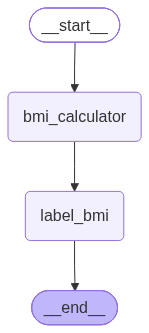

In [19]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())